# The Cobra Effect: When Marketing Metrics Bite Back

**Companion notebook for the Marketing Data Science article**
by Joe Domaleski, [Country Fried Creative](https://countryfriedcreative.com) | [blog.marketingdatascience.ai](https://blog.marketingdatascience.ai)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/joedom99/cobra-effect-for-marketers/blob/main/cobra_effect_for_marketers.ipynb)

---

## What this notebook does

Goodhart's Law says that when a measure becomes a target, it stops being a good measure. This notebook makes that idea visible with a simple simulation of a marketing team that gets paid a bonus for every lead it generates.

Here's the setup. A team has two ways to produce leads:

1. **Genuine prospecting.** Slower and more expensive, but these leads actually buy.
2. **Cheap tactics.** Contest entries, gated downloads nobody reads, form fills from bots and freebie hunters. Fast and cheap, but these leads almost never buy.

Sales has a fixed amount of time to follow up. They can't tell a good lead from a junk lead until they call it.

As we turn up the pressure on lead count, we'll watch what happens to lead count (the measure) and revenue (the thing we actually wanted).

## What's inside

1. Setup and assumptions
2. The proxy works, at first
3. Turning up the pressure: the signature chart
4. Why it happens: the lead mix
5. The correlation breaks down
6. The fix: pay for a better metric
7. Bonus: Goodhart without any cheaters (the winner's curse)
8. Summary

Everything here is simulated. The numbers are illustrative, not a benchmark. Every assumption lives in one place in Section 1, so you can change it and rerun the whole notebook.

## 1. Setup and assumptions

This notebook only uses libraries that come preinstalled in Google Colab: NumPy, pandas, and Matplotlib. The first cell sets a random seed so your results match mine exactly. (Reproducibility matters. I wrote a whole article about it.)

In [1]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

SEED = 42
rng = np.random.default_rng(SEED)

os.makedirs("figures", exist_ok=True)
print("NumPy", np.__version__, "| pandas", pd.__version__)

NumPy 2.1.3 | pandas 2.2.3


### Figure style

Figures use the Country Fried Creative color palette on a clean white background. The cell below tries to download the Lato font from Google Fonts. If that fails (for example, if you're offline), Matplotlib falls back to its default font and everything still works.

In [2]:
# Country Fried Creative brand palette
TEAL   = "#6db7ac"
ORANGE = "#f58235"
RED    = "#c02126"
NAVY   = "#212f3f"
GREEN  = "#198a53"
GOLD   = "#eec35b"
GRAY   = "#8a929b"

def load_lato():
    # Try to download and register Lato. Return True if it worked.
    base = "https://raw.githubusercontent.com/google/fonts/main/ofl/lato/"
    try:
        for style in ["Lato-Regular.ttf", "Lato-Bold.ttf"]:
            path = os.path.join("/tmp", style)
            if not os.path.exists(path):
                urllib.request.urlretrieve(base + style, path)
            font_manager.fontManager.addfont(path)
        return True
    except Exception as e:
        print("Could not load Lato, using the default font instead:", e)
        return False

HAS_LATO = load_lato()

plt.rcParams.update({
    "font.family": "Lato" if HAS_LATO else "DejaVu Sans",
    "font.size": 11,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": NAVY,
    "axes.labelcolor": NAVY,
    "axes.titlecolor": NAVY,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e8eb",
    "grid.linewidth": 0.8,
    "xtick.color": NAVY,
    "ytick.color": NAVY,
    "legend.frameon": False,
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

def save(fig, name):
    path = os.path.join("figures", name)
    fig.savefig(path)
    print("Saved", path)

def dollars_k(x, pos=None):
    return f"${x/1000:,.0f}k"

print("Font:", plt.rcParams["font.family"])

Font: ['Lato']


### The assumptions

Every number that drives the simulation is in the dictionary below. These are made up but realistic for a small B2B or local service business. Change any of them and rerun the notebook to see how the story changes.

A few to notice:

- A cheap lead costs one fifth of the effort of a genuine lead. That's what makes gaming attractive.
- A genuine lead converts at 12%. A cheap lead converts at 1%.
- Sales can follow up on 250 leads a month. Past that, they pick leads at random because they can't tell them apart.

In [3]:
ASSUMPTIONS = {
    # Marketing effort
    "base_effort": 100,          # effort units per month with no pressure
    "max_effort_boost": 0.80,    # pressure can raise effort up to +80% (people work harder)
    "effort_response": 3.0,      # how quickly effort responds to pressure

    # Cost of producing a lead, in effort units
    "cost_genuine": 1.0,         # one genuine lead takes 1 unit of effort
    "cost_cheap": 0.2,           # one cheap lead takes 0.2 units (5x easier)

    # How the team shifts toward cheap tactics
    "gaming_share_floor": 0.03,  # some junk leads always show up
    "gaming_share_max": 0.90,    # the most the team will ever game
    "gaming_half_point": 2.5,    # gaming incentive at which half the shift has happened
    "gaming_steepness": 3.0,     # how sharp the tipping point is

    # Sales and conversion
    "sales_capacity": 250,       # leads sales can follow up on per month
    "conv_genuine": 0.12,        # close rate for genuine leads
    "conv_cheap": 0.01,          # close rate for cheap leads
    "deal_value": 2500,          # revenue per closed deal

    # The fix: sales-accepted leads (SAL)
    "sal_pass_genuine": 0.95,    # share of genuine leads that pass qualification
    "sal_pass_cheap": 0.15,      # share of cheap leads that sneak through

    # Simulation
    "n_sims": 2000,              # Monte Carlo runs per pressure level
}

pd.Series(ASSUMPTIONS, name="value").to_frame()

,value
base_effort,100.00
max_effort_boost,0.80
effort_response,3.00
cost_genuine,1.00
cost_cheap,0.20
gaming_share_floor,0.03
gaming_share_max,0.90
gaming_half_point,2.50
gaming_steepness,3.00
sales_capacity,250.00


### How the team responds to pressure

Two things happen when you put a bounty on leads.

**People work harder.** That's the good part, and it's why incentives work at first. Effort rises with pressure, then levels off because there are only so many hours in a day.

**People find shortcuts.** How much the team games depends on two things: how much pressure there is, and how much more a shortcut pays than honest work. I call the product of those two the *gaming incentive*:

$$\text{gaming incentive} = \text{pressure} \times (R - 1)$$

where $R$ is how many more *counted* leads a unit of effort buys through shortcuts than through genuine prospecting. If shortcuts pay the same as honest work ($R = 1$) or less ($R < 1$), there's no reason to game.

The share of effort that goes to shortcuts follows an S-shaped curve. Nothing much happens at low pressure, then there's a tipping point, then most of the effort goes to gaming.

In [4]:
A = ASSUMPTIONS

def effort_multiplier(p):
    # Effort rises with pressure and levels off.
    return 1 + A["max_effort_boost"] * (1 - np.exp(-A["effort_response"] * p))

def payoff_ratio(incentive):
    # R: counted leads per unit of effort, shortcuts vs. genuine prospecting.
    if incentive == "raw_leads":
        cheap = 1 / A["cost_cheap"]
        genuine = 1 / A["cost_genuine"]
    elif incentive == "sal":
        cheap = A["sal_pass_cheap"] / A["cost_cheap"]
        genuine = A["sal_pass_genuine"] / A["cost_genuine"]
    else:
        raise ValueError(incentive)
    return cheap / genuine

def gaming_share(p, incentive):
    # Share of effort the team puts into cheap tactics.
    g = np.maximum(0.0, p * (payoff_ratio(incentive) - 1))
    n, h = A["gaming_steepness"], A["gaming_half_point"]
    hill = g**n / (g**n + h**n)
    return A["gaming_share_floor"] + (A["gaming_share_max"] - A["gaming_share_floor"]) * hill

for inc in ["raw_leads", "sal"]:
    print(f"{inc:>10}: R = {payoff_ratio(inc):.2f}")

 raw_leads: R = 5.00
       sal: R = 0.79


With a bounty on raw leads, shortcuts pay **5 times** more than honest prospecting. With a bounty on sales-accepted leads, shortcuts pay **less** than honest work because most junk gets caught at qualification. Hold onto that number. It's the whole story of Section 6.

### The simulation

For each pressure level, we run 2,000 simulated months. Each month:

1. The team splits its effort between genuine and cheap tactics.
2. Leads arrive with some randomness (Poisson counts).
3. If the incentive is sales-accepted leads, a qualification step filters leads first.
4. Sales follows up on as many leads as it has capacity for, chosen at random.
5. Each contacted lead closes or doesn't, based on its true quality (binomial draws).

This is a small Monte Carlo simulation. If you read my [Monte Carlo article](https://blog.marketingdatascience.ai/introduction-to-monte-carlo-simulation-for-marketers-8cb0077f1566), this will look familiar.

In [5]:
def simulate_month(p, incentive, n, rng):
    # Simulate n independent months at pressure level p. Returns a DataFrame.
    effort = A["base_effort"] * effort_multiplier(p)
    s = gaming_share(p, incentive)

    genuine = rng.poisson(effort * (1 - s) / A["cost_genuine"], n)
    cheap = rng.poisson(effort * s / A["cost_cheap"], n)

    if incentive == "sal":
        pool_genuine = rng.binomial(genuine, A["sal_pass_genuine"])
        pool_cheap = rng.binomial(cheap, A["sal_pass_cheap"])
    else:
        pool_genuine, pool_cheap = genuine, cheap

    pool = pool_genuine + pool_cheap
    contacted = np.minimum(pool, A["sales_capacity"])
    # Sales can't tell leads apart, so contacted leads are a random draw from the pool.
    contacted_genuine = rng.hypergeometric(pool_genuine, pool_cheap, contacted)
    contacted_cheap = contacted - contacted_genuine

    deals = (rng.binomial(contacted_genuine, A["conv_genuine"])
             + rng.binomial(contacted_cheap, A["conv_cheap"]))

    return pd.DataFrame({
        "pressure": p,
        "incentive": incentive,
        "gaming_share": s,
        "genuine_leads": genuine,
        "cheap_leads": cheap,
        "leads": genuine + cheap,
        "worked_leads": pool,
        "contacted": contacted,
        "deals": deals,
        "revenue": deals * A["deal_value"],
    })

pressures = np.round(np.linspace(0, 1, 41), 3)
sims = pd.concat(
    [simulate_month(p, inc, A["n_sims"], rng)
     for inc in ["raw_leads", "sal"] for p in pressures],
    ignore_index=True,
)

def q05(x): return x.quantile(0.05)
def q95(x): return x.quantile(0.95)

summary = (sims.groupby(["incentive", "pressure"])
               .agg(gaming_share=("gaming_share", "first"),
                    leads=("leads", "mean"),
                    leads_lo=("leads", q05), leads_hi=("leads", q95),
                    genuine_leads=("genuine_leads", "mean"),
                    cheap_leads=("cheap_leads", "mean"),
                    revenue=("revenue", "mean"),
                    rev_lo=("revenue", q05), rev_hi=("revenue", q95))
               .reset_index())

print(f"Simulated {len(sims):,} months")
summary[summary.incentive == "raw_leads"].iloc[::5].round(2)

Simulated 164,000 months


,incentive,pressure,gaming_share,leads,leads_lo,leads_hi,genuine_leads,cheap_leads,revenue,rev_lo,rev_hi
0,raw_leads,0.00,0.03,111.88,95.00,130.00,96.94,14.94,29368.75,17375.0,45000.0
5,raw_leads,0.12,0.04,143.39,124.00,162.00,120.46,22.93,36902.50,22500.0,52500.0
10,raw_leads,0.25,0.08,188.99,167.00,212.00,130.46,58.53,40478.75,25000.0,57500.0
15,raw_leads,0.38,0.18,267.96,242.00,295.00,125.92,142.04,38433.75,25000.0,55000.0
20,raw_leads,0.50,0.32,372.38,340.95,404.00,109.10,263.28,26231.25,15000.0,40000.0
25,raw_leads,0.62,0.46,480.08,444.00,516.05,90.01,390.07,19285.00,7500.0,32500.0
30,raw_leads,0.75,0.58,570.05,532.00,609.05,71.52,498.53,15192.50,5000.0,25000.0
35,raw_leads,0.88,0.67,639.52,599.00,682.00,58.18,581.34,12622.50,5000.0,22500.0
40,raw_leads,1.00,0.73,689.35,647.00,734.00,47.56,641.79,10943.75,2500.0,20000.0


## 2. The proxy works, at first

Before anyone puts a bounty on leads, lead count is a pretty good stand-in for revenue. More leads, more sales. That's why managers pick it as a target in the first place.

To show this, I'll simulate two years of monthly data from a team under light, everyday pressure (somewhere between 0 and 0.25 on our scale).

Saved figures/fig01_proxy_works.png


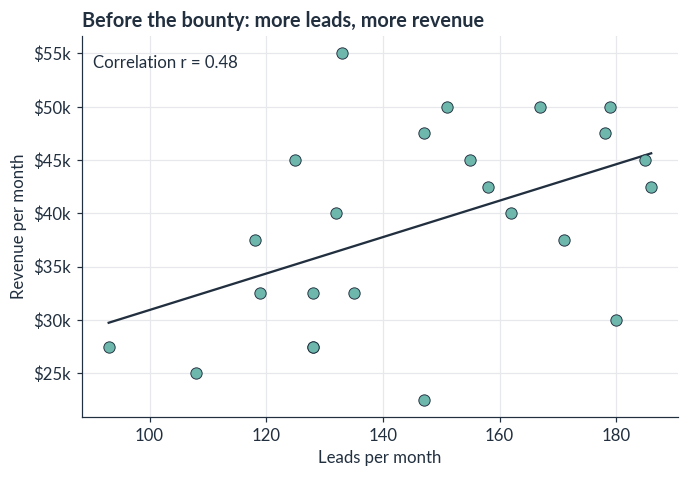

In [6]:
def sample_months(p_low, p_high, n_months, incentive, rng):
    ps = rng.uniform(p_low, p_high, n_months)
    return pd.concat([simulate_month(p, incentive, 1, rng) for p in ps], ignore_index=True)

calm = sample_months(0.0, 0.25, 24, "raw_leads", rng)
r_calm = calm["leads"].corr(calm["revenue"])

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(calm["leads"], calm["revenue"], s=55, color=TEAL, edgecolor=NAVY, linewidth=0.6, zorder=3)
b, a0 = np.polyfit(calm["leads"], calm["revenue"], 1)
xs = np.linspace(calm["leads"].min(), calm["leads"].max(), 50)
ax.plot(xs, a0 + b * xs, color=NAVY, linewidth=1.5, zorder=2)
ax.yaxis.set_major_formatter(dollars_k)
ax.set_xlabel("Leads per month")
ax.set_ylabel("Revenue per month")
ax.set_title("Before the bounty: more leads, more revenue")
ax.text(0.02, 0.95, f"Correlation r = {r_calm:.2f}", transform=ax.transAxes,
        va="top", color=NAVY, fontsize=11)
save(fig, "fig01_proxy_works.png")
plt.show()

Under normal conditions, the correlation is clearly positive. It's noisy, because closing deals always involves some luck, but the direction is obvious. If you only looked at this chart, paying people for leads would seem like a smart idea.

## 3. Turning up the pressure: the signature chart

Now let's tie a bonus to lead count and increase the pressure from 0 (no lead target) to 1 (the lead number is all anyone gets judged on).

The top panel is what the dashboard shows. The bottom panel is what the bank account shows. Shaded bands cover 90% of the simulated months.

Saved figures/fig02_signature_chart.png


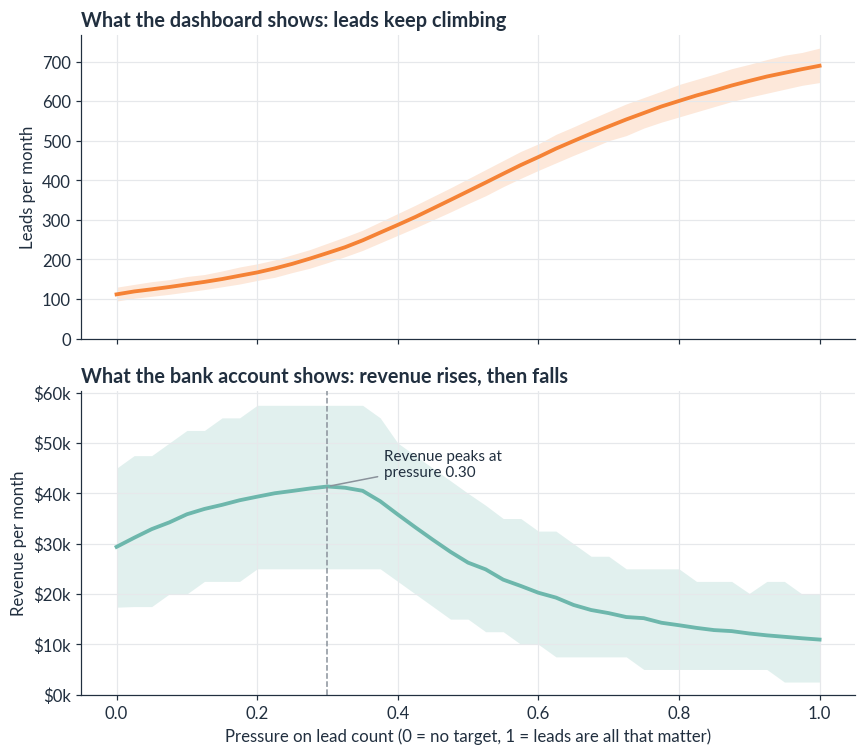

No pressure:      112 leads  $   29,369 revenue
Revenue peak:     216 leads  $   41,364 revenue  (pressure 0.30)
Max pressure:     689 leads  $   10,944 revenue


In [7]:
raw = summary[summary.incentive == "raw_leads"].reset_index(drop=True)
peak = raw.loc[raw["revenue"].idxmax()]
base = raw.iloc[0]
top = raw.iloc[-1]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

ax1.fill_between(raw.pressure, raw.leads_lo, raw.leads_hi, color=ORANGE, alpha=0.18, linewidth=0)
ax1.plot(raw.pressure, raw.leads, color=ORANGE, linewidth=2.5)
ax1.set_ylabel("Leads per month")
ax1.set_title("What the dashboard shows: leads keep climbing")
ax1.set_ylim(bottom=0)

ax2.fill_between(raw.pressure, raw.rev_lo, raw.rev_hi, color=TEAL, alpha=0.2, linewidth=0)
ax2.plot(raw.pressure, raw.revenue, color=TEAL, linewidth=2.5)
ax2.axvline(peak.pressure, color=GRAY, linestyle="--", linewidth=1)
ax2.annotate(f"Revenue peaks at\npressure {peak.pressure:.2f}",
             xy=(peak.pressure, peak.revenue), xytext=(peak.pressure + 0.08, peak.revenue * 1.05),
             color=NAVY, fontsize=10, arrowprops=dict(arrowstyle="-", color=GRAY))
ax2.yaxis.set_major_formatter(dollars_k)
ax2.set_ylabel("Revenue per month")
ax2.set_xlabel("Pressure on lead count (0 = no target, 1 = leads are all that matter)")
ax2.set_title("What the bank account shows: revenue rises, then falls")
ax2.set_ylim(bottom=0)

fig.tight_layout()
save(fig, "fig02_signature_chart.png")
plt.show()

print(f"No pressure:   {base.leads:6.0f} leads  ${base.revenue:>9,.0f} revenue")
print(f"Revenue peak:  {peak.leads:6.0f} leads  ${peak.revenue:>9,.0f} revenue  (pressure {peak.pressure:.2f})")
print(f"Max pressure:  {top.leads:6.0f} leads  ${top.revenue:>9,.0f} revenue")

This is the cobra effect in one picture.

At first, the incentive works. People try harder, leads go up, and revenue goes up with them. Then the team hits a tipping point. Leads keep climbing, and every monthly report looks better than the last. Meanwhile revenue falls below where it started before anyone had a lead target at all.

Nobody in this simulation is lazy or dishonest in a dramatic way. They're responding rationally to what the company is paying for.

## 4. Why it happens: the lead mix

Lead count alone hides what's going on inside the number. Splitting leads into genuine and cheap shows the mechanism.

Saved figures/fig03_lead_mix.png


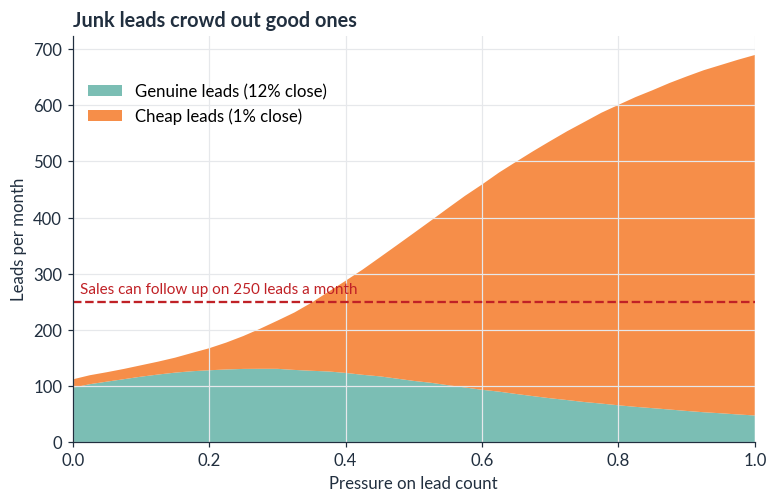

Pressure 0.00:  3.0% of effort on cheap tactics,   97 genuine and   15 cheap leads
Pressure 0.30: 11.7% of effort on cheap tactics,  131 genuine and   86 cheap leads
Pressure 1.00: 72.9% of effort on cheap tactics,   48 genuine and  642 cheap leads


In [8]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.stackplot(raw.pressure, raw.genuine_leads, raw.cheap_leads,
             colors=[TEAL, ORANGE], alpha=0.9,
             labels=["Genuine leads (12% close)", "Cheap leads (1% close)"])
ax.axhline(A["sales_capacity"], color=RED, linestyle="--", linewidth=1.5)
ax.text(0.01, A["sales_capacity"] + 15, f"Sales can follow up on {A['sales_capacity']} leads a month",
        color=RED, fontsize=10)
ax.set_xlabel("Pressure on lead count")
ax.set_ylabel("Leads per month")
ax.set_title("Junk leads crowd out good ones")
ax.set_xlim(0, 1)
ax.set_ylim(bottom=0)
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.92))
save(fig, "fig03_lead_mix.png")
plt.show()

for p in [0.0, peak.pressure, 1.0]:
    row = raw.loc[(raw.pressure - p).abs().idxmin()]
    print(f"Pressure {row.pressure:.2f}: {row.gaming_share:5.1%} of effort on cheap tactics, "
          f"{row.genuine_leads:4.0f} genuine and {row.cheap_leads:4.0f} cheap leads")

Two things go wrong at once.

1. **Effort moves to shortcuts.** Every hour spent on a cheap lead is an hour not spent finding a genuine one. Genuine leads actually *decline* at high pressure.
2. **Junk swamps sales.** Once leads pass sales capacity (the red line), sales can only work a random slice of the pile. The more junk there is, the fewer good leads get a call.

The metric didn't just stop measuring what we wanted. It started actively pulling against it.

## 5. The correlation breaks down

Goodhart's Law has a precise statistical meaning. The relationship between a proxy and the goal is not a law of nature. It holds under the conditions where you observed it, and it can change when you change the conditions.

Let's compare two years of monthly data under light pressure with two years under heavy pressure.

Saved figures/fig04_correlation_breakdown.png


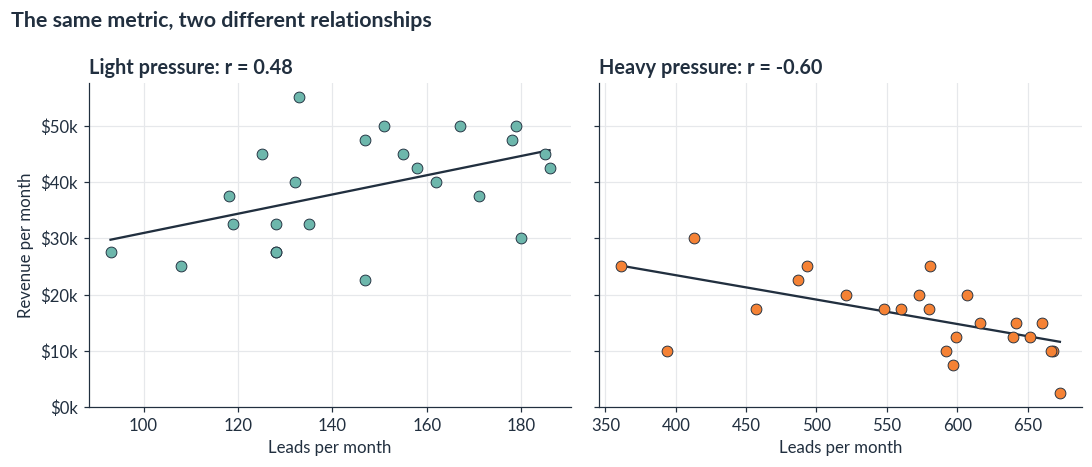

Correlation between leads and revenue, light pressure: +0.48
Correlation between leads and revenue, heavy pressure: -0.60


In [9]:
heavy = sample_months(0.5, 1.0, 24, "raw_leads", rng)
r_heavy = heavy["leads"].corr(heavy["revenue"])

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3), sharey=True)
panels = [(axes[0], calm, r_calm, TEAL, "Light pressure"),
          (axes[1], heavy, r_heavy, ORANGE, "Heavy pressure")]
for ax, d, r, c, title in panels:
    ax.scatter(d["leads"], d["revenue"], s=50, color=c, edgecolor=NAVY, linewidth=0.6, zorder=3)
    b, a0 = np.polyfit(d["leads"], d["revenue"], 1)
    xs = np.linspace(d["leads"].min(), d["leads"].max(), 50)
    ax.plot(xs, a0 + b * xs, color=NAVY, linewidth=1.5)
    ax.set_title(f"{title}: r = {r:.2f}")
    ax.set_xlabel("Leads per month")
    ax.yaxis.set_major_formatter(dollars_k)
axes[0].set_ylabel("Revenue per month")
axes[0].set_ylim(bottom=0)
fig.suptitle("The same metric, two different relationships", x=0.01, ha="left",
             fontweight="bold", color=NAVY, fontsize=14)
fig.tight_layout()
save(fig, "fig04_correlation_breakdown.png")
plt.show()

print(f"Correlation between leads and revenue, light pressure: {r_calm:+.2f}")
print(f"Correlation between leads and revenue, heavy pressure: {r_heavy:+.2f}")

Under light pressure, more leads means more revenue. Under heavy pressure, the relationship flips. The months with the *most* leads are the months with the *least* revenue.

This is why a model trained on last year's data can fail when you start optimizing against it. The act of targeting the metric changed the system that produced the data. If you read my article on [reproducibility, replicability, and generalizability](https://blog.marketingdatascience.ai/reproducibility-replicability-and-generalizability-in-digital-marketing-analytics-c43bad85dc07), this is a generalizability failure.

## 6. The fix: pay for a better metric

What if we keep the bonus and the pressure but change what counts? Instead of paying for every lead, pay for **sales-accepted leads (SAL)**: leads that pass a quick qualification check by the sales team.

Nothing else changes. Same people, same pressure, same effort boost. (To keep the chart readable, I've left off the 90% bands here. The averages tell the story.)

Saved figures/fig05_the_fix.png


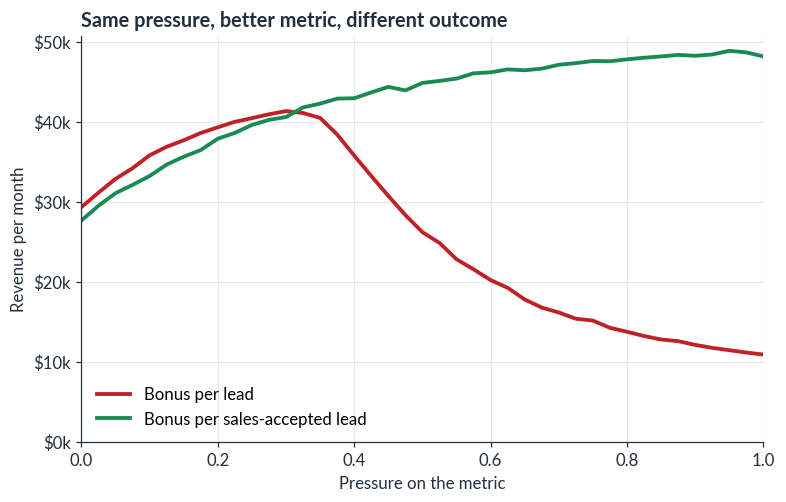

At maximum pressure:


,Bonus per lead,Bonus per SAL
Effort on cheap tactics,0.73,0.03
Raw leads per month,689.35,196.92
Revenue per month,10943.75,48186.25


In [10]:
sal = summary[summary.incentive == "sal"].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(raw.pressure, raw.revenue, color=RED, linewidth=2.5, label="Bonus per lead")
ax.plot(sal.pressure, sal.revenue, color=GREEN, linewidth=2.5, label="Bonus per sales-accepted lead")
ax.yaxis.set_major_formatter(dollars_k)
ax.set_xlabel("Pressure on the metric")
ax.set_ylabel("Revenue per month")
ax.set_title("Same pressure, better metric, different outcome")
ax.set_xlim(0, 1)
ax.set_ylim(bottom=0)
ax.legend(loc="lower left")
save(fig, "fig05_the_fix.png")
plt.show()

compare = pd.DataFrame({
    "Bonus per lead": [raw.iloc[-1].gaming_share, raw.iloc[-1].leads, raw.iloc[-1].revenue],
    "Bonus per SAL": [sal.iloc[-1].gaming_share, sal.iloc[-1].leads, sal.iloc[-1].revenue],
}, index=["Effort on cheap tactics", "Raw leads per month", "Revenue per month"])
print("At maximum pressure:")
compare.round(2)

The difference comes down to the payoff ratio from Section 1. When the bonus is per lead, a shortcut pays 5 times more than honest work. When the bonus is per sales-accepted lead, most junk gets caught at qualification, so a shortcut pays *less* than honest work. Gaming stops being rational.

Under the better metric, pressure does what managers hoped it would: people work harder, and revenue rises and holds.

A few honest caveats:

- SAL is still a proxy. A determined team could learn to game qualification too (and a sales team grading its own inputs has incentives of its own). Every metric can be gamed eventually. The goal is to make gaming harder than doing the real work.
- Moving the metric closer to the outcome (opportunities, closed revenue, customer lifetime value) makes gaming harder still, but the feedback gets slower.
- Pairing metrics helps. Leads *and* close rate. CTR *and* conversion rate. One number pulls, the other pushes back.

## 7. Bonus: Goodhart without any cheaters

So far, the problem came from people gaming the metric. But Goodhart's Law can bite even when everyone is honest.

Say you test 30 new ad concepts, each shown to 500 visitors in a pilot. You pick the one with the best measured conversion rate and roll it out. How well will it do?

Each concept has a true conversion rate, and the pilot gives you a noisy measurement of it. When you pick the *highest* measurement, you're selecting partly for real quality and partly for good luck. The luck doesn't come with you into the rollout. This is often called the winner's curse or the optimizer's curse.

Saved figures/fig06_winners_curse.png


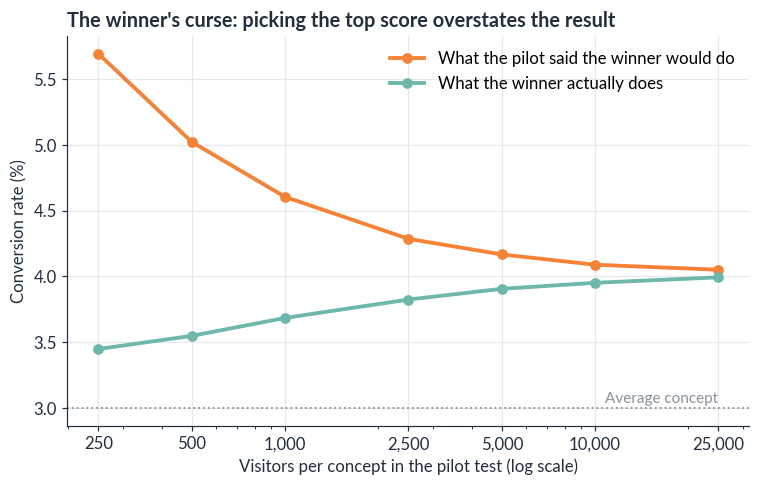

,pilot_size,pilot rate %,true rate %,picked true best %,overstated by %
0,250,5.69,3.45,14.4,65.1
1,500,5.02,3.55,19.0,41.6
2,1000,4.60,3.68,27.4,25.0
3,2500,4.29,3.82,41.0,12.1
4,5000,4.17,3.91,52.6,6.7
5,10000,4.09,3.95,62.2,3.5
6,25000,4.05,3.99,75.8,1.4


In [11]:
N_CONCEPTS = 30
TRUE_MEAN, TRUE_SD = 0.030, 0.005   # true conversion rates around 3%
N_TRIALS = 5000

def winners_curse(pilot_size, rng):
    true_rates = np.clip(rng.normal(TRUE_MEAN, TRUE_SD, (N_TRIALS, N_CONCEPTS)), 0.001, None)
    measured = rng.binomial(pilot_size, true_rates) / pilot_size
    pick = measured.argmax(axis=1)
    rows = np.arange(N_TRIALS)
    return pd.DataFrame({
        "pilot_size": pilot_size,
        "measured": measured[rows, pick],
        "true": true_rates[rows, pick],
        "picked_best": pick == true_rates.argmax(axis=1),
    })

sizes = [250, 500, 1000, 2500, 5000, 10000, 25000]
wc = pd.concat([winners_curse(n, rng) for n in sizes], ignore_index=True)
wc_sum = (wc.groupby("pilot_size")
            .agg(measured=("measured", "mean"), true=("true", "mean"),
                 picked_best=("picked_best", "mean"))
            .reset_index())
wc_sum["overstatement"] = wc_sum["measured"] / wc_sum["true"] - 1

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(wc_sum.pilot_size, wc_sum.measured * 100, "o-", color=ORANGE, linewidth=2.5,
        label="What the pilot said the winner would do")
ax.plot(wc_sum.pilot_size, wc_sum.true * 100, "o-", color=TEAL, linewidth=2.5,
        label="What the winner actually does")
ax.axhline(TRUE_MEAN * 100, color=GRAY, linestyle=":", linewidth=1.2)
ax.text(sizes[-1], TRUE_MEAN * 100 + 0.04, "Average concept", color=GRAY, ha="right", fontsize=10)
ax.set_xscale("log")
ax.set_xticks(sizes)
ax.set_xticklabels([f"{s:,}" for s in sizes])
ax.set_xlabel("Visitors per concept in the pilot test (log scale)")
ax.set_ylabel("Conversion rate (%)")
ax.set_title("The winner's curse: picking the top score overstates the result")
ax.legend(loc="upper right")
save(fig, "fig06_winners_curse.png")
plt.show()

wc_sum.assign(measured=lambda d: (d.measured * 100).round(2),
              true=lambda d: (d.true * 100).round(2),
              overstatement=lambda d: (d.overstatement * 100).round(1),
              picked_best=lambda d: (d.picked_best * 100).round(1)) \
      .rename(columns={"measured": "pilot rate %", "true": "true rate %",
                       "overstatement": "overstated by %", "picked_best": "picked true best %"})

With small pilots, the winning concept looks much better than it really is, and you often don't even pick the true best one. The gap shrinks as tests get bigger, because there's less luck to select on.

Nobody cheated here. The overstatement comes purely from optimizing on a noisy measurement. This is also why the best-performing campaign from last quarter so often disappoints this quarter. (See my article on [regression to the mean](https://blog.marketingdatascience.ai/regression-to-the-mean-the-statistical-force-that-humbles-marketers-61382f3e1ceb).)

## 8. Summary

In [12]:
results = pd.DataFrame([
    ["Revenue with no lead target", f"${base.revenue:,.0f}"],
    ["Peak revenue under a lead bonus", f"${peak.revenue:,.0f} at pressure {peak.pressure:.2f}"],
    ["Revenue at max pressure, lead bonus", f"${top.revenue:,.0f}"],
    ["Leads at max pressure vs. no target", f"{top.leads:,.0f} vs. {base.leads:,.0f} ({top.leads / base.leads:.1f}x)"],
    ["Effort on cheap tactics at max pressure", f"{top.gaming_share:.0%}"],
    ["Leads/revenue correlation, light vs. heavy pressure", f"{r_calm:+.2f} vs. {r_heavy:+.2f}"],
    ["Revenue at max pressure, SAL bonus", f"${sal.iloc[-1].revenue:,.0f}"],
    ["Winner's curse overstatement, 500-visitor pilot",
     f"{wc_sum.loc[wc_sum.pilot_size == 500, 'overstatement'].iloc[0]:.0%}"],
], columns=["Result", "Value"])
results

,Result,Value
0,Revenue with no lead target,"$29,369"
1,Peak revenue under a lead bonus,"$41,364 at pressure 0.30"
2,"Revenue at max pressure, lead bonus","$10,944"
3,Leads at max pressure vs. no target,689 vs. 112 (6.2x)
4,Effort on cheap tactics at max pressure,73%
5,"Leads/revenue correlation, light vs. heavy pre...",+0.48 vs. -0.60
6,"Revenue at max pressure, SAL bonus","$48,186"
7,"Winner's curse overstatement, 500-visitor pilot",42%


### Takeaways

1. **Every metric is a proxy.** Lead count, CTR, followers, and reviews stand in for something you actually care about. They track it under normal conditions.
2. **Pressure changes the system.** Once a metric becomes a target, people (and algorithms) find the cheapest way to move it. That's rational, not evil.
3. **The dashboard can improve while the business gets worse.** Watch for numbers that improve faster than the outcomes they're supposed to predict.
4. **Correlations you measured before the target may not survive the target.**
5. **Design the metric so honest work is the easiest way to win.** Measure closer to the outcome, pair volume with quality, and ask "if I were trying to game this, how would I do it?" before you launch an incentive.
6. **Goodhart can bite even without cheaters.** Picking winners from noisy measurements overstates how good they are.

### Try it yourself

Go back to the `ASSUMPTIONS` cell and experiment:

- Raise `sales_capacity` to 1,000. Does the revenue collapse go away, or just move?
- Set `cost_cheap` to 1.0 so shortcuts are no easier than real work. What happens to gaming?
- Raise `sal_pass_cheap` to 0.5. How sloppy can qualification get before the fix stops working?

### Related articles

- [Vanity Metrics: You Can't Deposit Likes at the Bank](https://blog.marketingdatascience.ai/vanity-metrics-you-cant-deposit-likes-at-the-bank-7592eadf91dc)
- [Introducing the Marketing Analytics Credibility Model (MACM)](https://blog.marketingdatascience.ai/introducing-the-marketing-analytics-credibility-model-macm-0700dea3c08e)
- [Regression to the Mean: The Statistical Force That Humbles Marketers](https://blog.marketingdatascience.ai/regression-to-the-mean-the-statistical-force-that-humbles-marketers-61382f3e1ceb)
- [Introduction to Monte Carlo Simulation for Marketers](https://blog.marketingdatascience.ai/introduction-to-monte-carlo-simulation-for-marketers-8cb0077f1566)
- [Is Your Marketing Model Too Accurate?](https://blog.marketingdatascience.ai/is-your-marketing-model-too-accurate-5076f5163326)

---

*Joe Domaleski is the founder of Country Fried Creative, a digital marketing agency in Peachtree City, Georgia. He holds an MBA and an MS in Analytics from Georgia Tech.*